<a href="https://colab.research.google.com/github/mybenkhadda/WildSpeech/blob/main/WildSpeech_M8/notebooks/WILDSPEECH_M82_PAIRWISE_MASTER.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# WildSpeech M8.2 — Multiview Pairwise Consensus & Outcome-Adjusted Student Discovery

**One-click GitHub source → cached M8.1 features → independent multi-view clustering → 146,070 pairs → stability and confounder audit → outcome-residual analysis → optional OOF predictive test → 12+ figures and a reproducible report.**

Research safety: score labels are **not** used to define clusters or build the consensus matrix; residuals are computed out of fold, and the predictor trains supervised components exclusively within each training partition. School IDs are used only for validation and confounder analysis. Audio is not reprocessed here.

Start in `SMOKE` to verify paths, then set `MODE='FULL'` for the complete research run. **SMOKE produces incomplete consensus, not a research conclusion.**

## 0 — GitHub-first setup and dependencies

In [12]:
from pathlib import Path
import os,sys,subprocess,importlib
REPO = 'https://github.com/mybenkhadda/WildSpeech.git'
REF = 'main'
REPO_ROOT = Path('/content/WildSpeech_M82_git') if Path('/content').exists() else Path.cwd()
if Path('/content').exists():
    if not (REPO_ROOT/'.git').exists():
        if REPO_ROOT.exists():
            raise RuntimeError(f'{REPO_ROOT} exists but is not a repository; choose another path')
        subprocess.check_call(['git','clone','--depth','1','--branch',REF,REPO,str(REPO_ROOT)])
    else:
        subprocess.check_call(['git','-C',str(REPO_ROOT),'pull','--ff-only','origin',REF])
PROJECT_ROOT = REPO_ROOT/'WildSpeech_M8'
if not (PROJECT_ROOT/'src'/'wildspeech_m8'/'m82_pipeline.py').is_file():
    raise FileNotFoundError(f'M8.2 modules missing at {PROJECT_ROOT}. Verify main includes the M8.2 commit.')
subprocess.check_call([sys.executable,'-m','pip','install','-q','-e',str(PROJECT_ROOT)+'[test]'])
src=str((PROJECT_ROOT/'src').resolve())
if src not in sys.path:sys.path.insert(0,src)
importlib.invalidate_caches()
import wildspeech_m8
print('Installed version:',wildspeech_m8.__version__,'source:',wildspeech_m8.__file__)
assert wildspeech_m8.__version__>='0.8.2'


Installed version: 0.8.2 source: /content/WildSpeech_M82_git/WildSpeech_M8/src/wildspeech_m8/__init__.py


## 1 — Mount Drive and select experiment settings

In [13]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Local runtime; Google Drive mount not needed')

DATA_ROOT=Path(os.environ.get('WILDSPEECH_DATA_ROOT','/content/drive/MyDrive/WildSpeech'))
OUTPUT_ROOT=Path(os.environ.get('M8_OUTPUT_ROOT','/content/drive/MyDrive/WildSpeech_M8'))
PROFILE_CSV=os.environ.get('M71_PROFILE_CSV','')
MODE='FULL' # Change to 'FULL' after the quick check.
RESAMPLES=5 # Full: runs per combination of cluster count and algorithm; 2 in smoke.
MAX_PER_VIEW=36
RUN_PREDICTIVE=True # Adds nested, training-only OOF residual comparison (extra compute).
print('data:',DATA_ROOT,'outputs:',OUTPUT_ROOT,'mode:',MODE,'profile:',PROFILE_CSV or 'auto-discover')
assert (DATA_ROOT/'train_student_metadata.csv').is_file(),f'Missing official metadata: {DATA_ROOT}'


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
data: /content/drive/MyDrive/WildSpeech outputs: /content/drive/MyDrive/WildSpeech_M8 mode: FULL profile: auto-discover


## 2 — Validate feature bank without re-extracting audio

In [14]:
from wildspeech_m8.m8_pipeline import Config,prepare_dataset,discover_profile
from wildspeech_m8.m82_views import ViewBuilder
import pandas as pd, numpy as np
from IPython.display import display,Image,Markdown,HTML
cfg_m81=Config(data_root=str(DATA_ROOT),output_root=str(OUTPUT_ROOT),profile_csv=PROFILE_CSV,
               quick=MODE=='SMOKE',max_features=450)
frame,test_frame,y,schools,submission,clips,manifest=prepare_dataset(cfg_m81)
print('Students:',len(frame),'test:',len(test_frame),'features:',frame.shape[1],
      'schools:',len(np.unique(schools)),'possible pairs:',len(frame)*(len(frame)-1)//2)
print('M7 profile:',discover_profile(cfg_m81))
display(manifest.groupby('family').agg(features=('feature','size'),missing=('train_missing','mean')))
print('Cached audio:',(OUTPUT_ROOT/'tables'/'audio_student_features.csv').exists())
print('Cached phonetics:',(OUTPUT_ROOT/'tables'/'phonetic_student_features.csv').exists())


/content/WildSpeech_M82_git/WildSpeech_M8/src/wildspeech_m8/m8_pipeline.py:142: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out['m8__sqrt__'+c]=np.sqrt(x.clip(lower=0))
/content/WildSpeech_M82_git/WildSpeech_M8/src/wildspeech_m8/m8_pipeline.py:142: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out['m8__sqrt__'+c]=np.sqrt(x.clip(lower=0))
/content/WildSpeech_M82_git/WildSpeech_M8/src/wildspeech_m8/m8_pipeline.py:142: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many t

Students: 541 test: 361 features: 448 schools: 17 possible pairs: 146070
M7 profile: /content/drive/MyDrive/WildSpeech_M7_DEEP_EDA/tables/student_profiles_all_covariates.csv


,features,missing
family,,
audio,325,0.095504
context_behavior,33,0.085028
screening,33,0.125525
speech_text,26,0.120148
temporal,31,0.090513


Cached audio: True
Cached phonetics: False


## 3 — Inspect independent views, coverage, and excluded nuisance variables

In [15]:
builder=ViewBuilder(max_per_view=MAX_PER_VIEW).fit(frame)
views=builder.transform(frame,include_nuisance=True)
for name,v in views.items():
    print(f'{name}: {len(v.columns)} columns, {100*v.observed.mean():.1f}% observed')
    print('   '+', '.join(v.columns[:8]))
print('NOTE: nuisance_audit is NEVER used to construct the student consensus.')
assert len([v for v in views if v!='nuisance_audit'])>=2,'Insufficient independent feature families'


screening: 25 columns, 87.2% observed
   blending__accuracy, blending_theta, deletion__accuracy, deletion_theta, m8__contrast__blending_theta__deletion_theta, m8__contrast__blending_theta__sentence_repetition_theta, m8__contrast__deletion_theta__sentence_repetition_theta, sentence_repetition__accuracy
task_behavior: 21 columns, 90.9% observed
   blending__missing_fraction, blending__n_clips, blending__ref_chars_mean, blending__ref_cluster_proxy_mean, blending__ref_syllable_proxy_mean, deletion__missing_fraction, deletion__n_clips, deletion__ref_chars_mean
acoustic_timing: 36 columns, 70.2% observed
   m8__taskcontrast__m8_audio_task_onset_s_proxy__blending_minus_deletion, m8__taskcontrast__m8_audio_task_onset_s_proxy__blending_minus_sentence_repetition, m8__taskcontrast__m8_audio_task_onset_s_proxy__deletion_minus_sentence_repetition, m8__taskcontrast__m8_audio_task_pause_count_proxy__blending_minus_deletion, m8__taskcontrast__m8_audio_task_pause_count_proxy__blending_minus_sentence_re

## 4 — Run the full M8.2 consensus and analysis experiment

In [16]:
from wildspeech_m8.m82_pipeline import M82Config,run_m82
run_cfg=M82Config(data_root=str(DATA_ROOT),output_root=str(OUTPUT_ROOT),profile_csv=PROFILE_CSV,
                  mode=MODE,max_features=450,max_per_view=MAX_PER_VIEW,
                  resamples=RESAMPLES,run_predictive=RUN_PREDICTIVE,
                  predictive_folds=5,predictive_repeats=1,seed=2026)
summary=run_m82(run_cfg)
OUT=OUTPUT_ROOT/'m82';T=OUT/'tables';F=OUT/'figures'
print(summary)


/content/WildSpeech_M82_git/WildSpeech_M8/src/wildspeech_m8/m8_pipeline.py:142: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out['m8__sqrt__'+c]=np.sqrt(x.clip(lower=0))
/content/WildSpeech_M82_git/WildSpeech_M8/src/wildspeech_m8/m8_pipeline.py:142: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out['m8__sqrt__'+c]=np.sqrt(x.clip(lower=0))
/content/WildSpeech_M82_git/WildSpeech_M8/src/wildspeech_m8/m8_pipeline.py:142: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many t

[M8.2] Cross-fitting screening-only prediction residuals
[M8.2] n_students=541 possible_pairs=146070 views=['screening', 'task_behavior', 'acoustic_timing', 'acoustic_signal', 'phonetic_speech', 'conditional_speech']
[M8.2] Testing inductive prototype residual model vs identical global baseline
[M8.2 DONE] 146070 pairs 17 figures in /content/drive/MyDrive/WildSpeech_M8/m82
{'version': 'M8.2', 'mode': 'FULL', 'students': 541, 'pairs': 146070, 'views': ['screening', 'task_behavior', 'acoustic_timing', 'acoustic_signal', 'phonetic_speech', 'conditional_speech'], 'nuisance_excluded_columns': 36, 'pair_categories': {'uncertain': 111975, 'cross_view_disagreement': 31224, 'stable_together': 2618, 'stable_apart': 253}, 'figures': ['M82_01_consensus_heatmap.png', 'M82_02_view_00_screening.png', 'M82_02_view_01_task_behavior.png', 'M82_02_view_02_acoustic_timing.png', 'M82_02_view_03_acoustic_signal.png', 'M82_02_view_04_phonetic_speech.png', 'M82_02_view_05_conditional_speech.png', 'M82_03_cons

## 5 — Pair category statistics and view coverage

,category,n_pairs,n_students_involved,pct_all_pairs,mean_consensus,mean_chance_excess,same_school_fraction,mean_screening_distance,median_score_gap,mean_score_gap,median_screening_residual_gap,mean_screening_residual_gap
0,uncertain,111975,541,0.7666,0.3695,-0.0301,0.1213,1.6335,9.0,11.9188,8.3615,10.7601
1,cross_view_disagreement,31224,541,0.2138,0.4671,0.0697,0.1511,1.6623,9.0,11.5932,8.1454,10.7930
2,stable_together,2618,180,0.0179,0.9563,0.5537,0.2452,0.7164,9.0,12.3113,9.3130,12.0882
3,stable_apart,253,151,0.0017,0.0613,-0.3315,0.1067,2.2927,11.0,13.1818,8.0352,10.2043


,view,n_features,n_runs_complete,pairs_supported,supported_fraction,mean_consensus,mean_null_expected
0,screening,25,75,145720,0.9976,0.4148,0.4145
1,task_behavior,21,75,146070,1.0000,0.3745,0.3737
2,acoustic_timing,36,75,47895,0.3279,0.2919,0.2918
3,acoustic_signal,36,75,146070,1.0000,0.3709,0.3709
4,phonetic_speech,20,75,145341,0.9950,0.4357,0.4357
5,conditional_speech,92,75,132738,0.9087,0.3978,0.3987


,category,n_pairs_matched,median_residual_gap_matched,mean_residual_gap_matched,mean_outcome_gap_matched,same_school_fraction_matched
0,stable_together,2236,9.3336,11.8191,11.7227,0.2428
1,stable_apart,17,7.6523,8.9225,11.3529,0.0000
2,cross_view_disagreement,7644,8.4126,11.4802,11.2645,0.1690
3,uncertain,26621,8.0987,10.3417,10.4357,0.1431


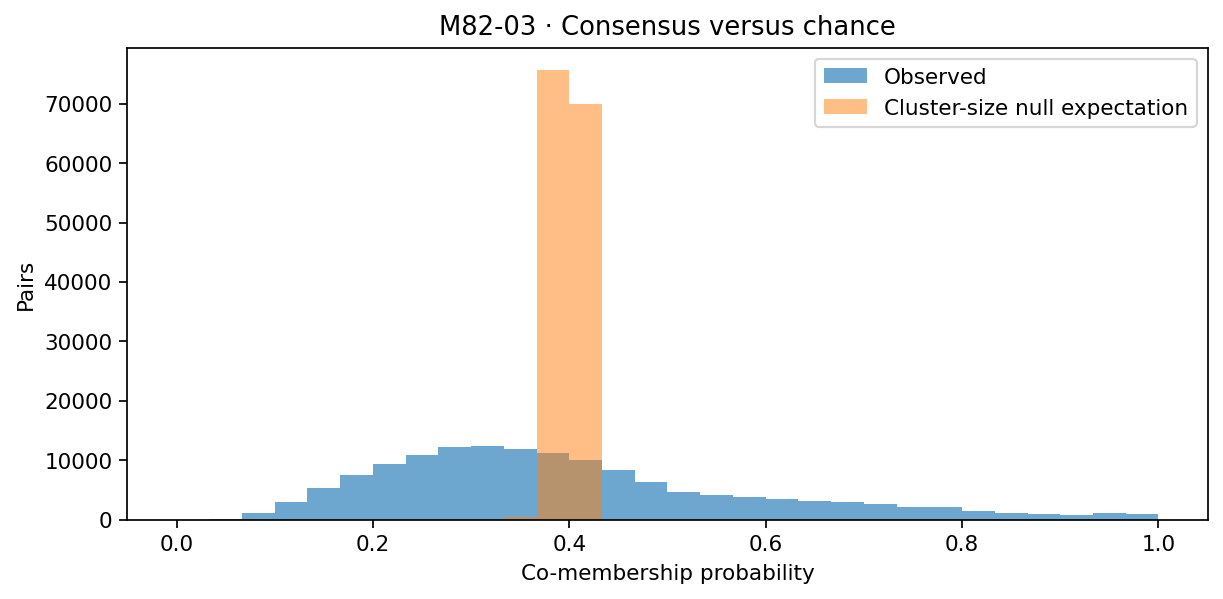

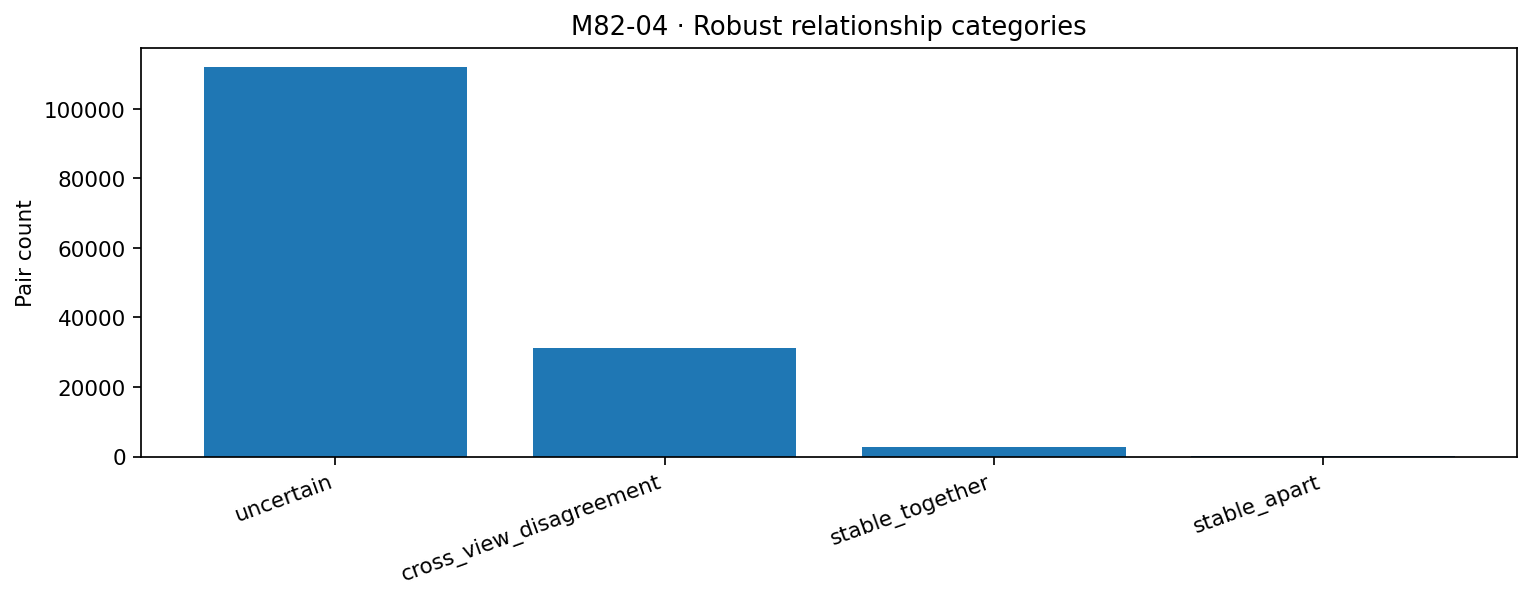

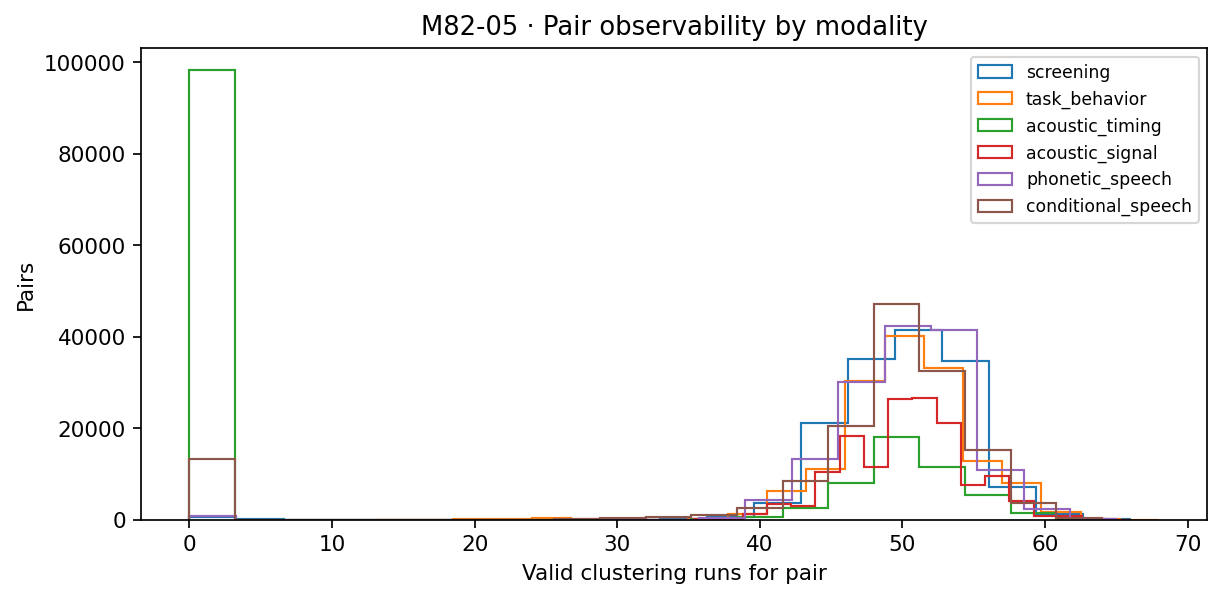

In [17]:
display(pd.read_csv(T/'pair_category_summary.csv').round(4))
display(pd.read_csv(T/'view_ensemble_summary.csv').round(4))
display(pd.read_csv(T/'ability_matched_pair_summary.csv').round(4))
for name in ('M82_03_consensus_vs_chance.png','M82_04_pair_categories.png','M82_05_pair_coverage.png'):
    if (F/name).is_file():display(Image(filename=str(F/name)))


## 6 — Global coassociation heatmap and one heatmap per feature family

M82_01_consensus_heatmap.png


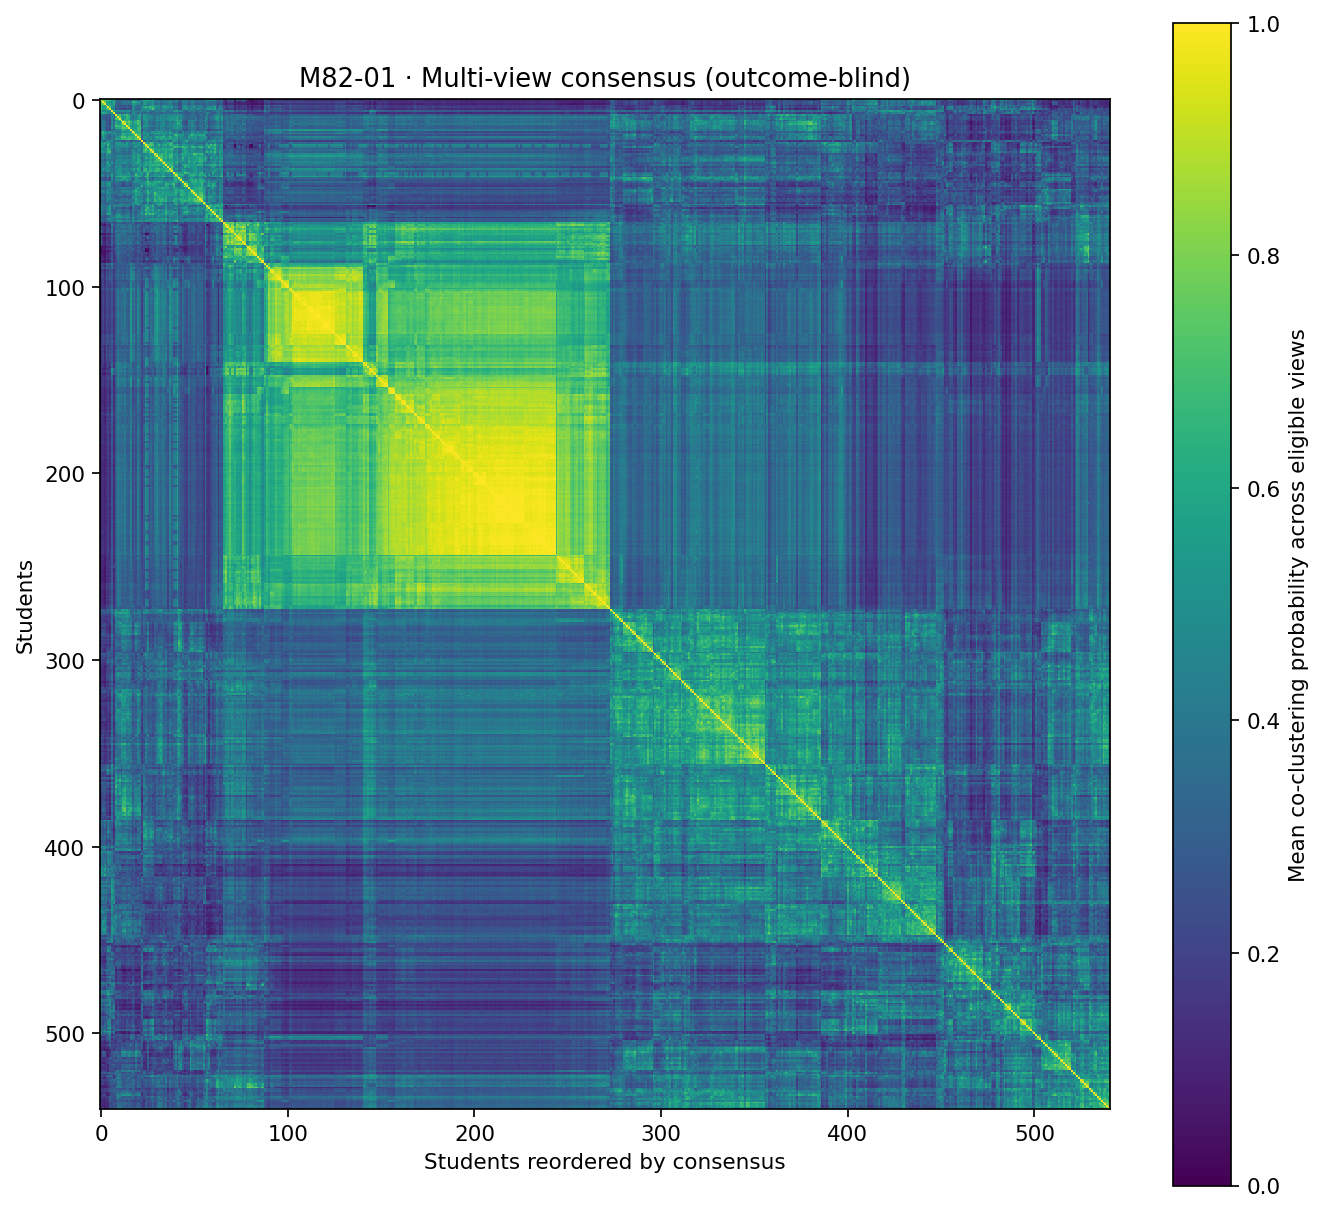

M82_02_view_00_screening.png


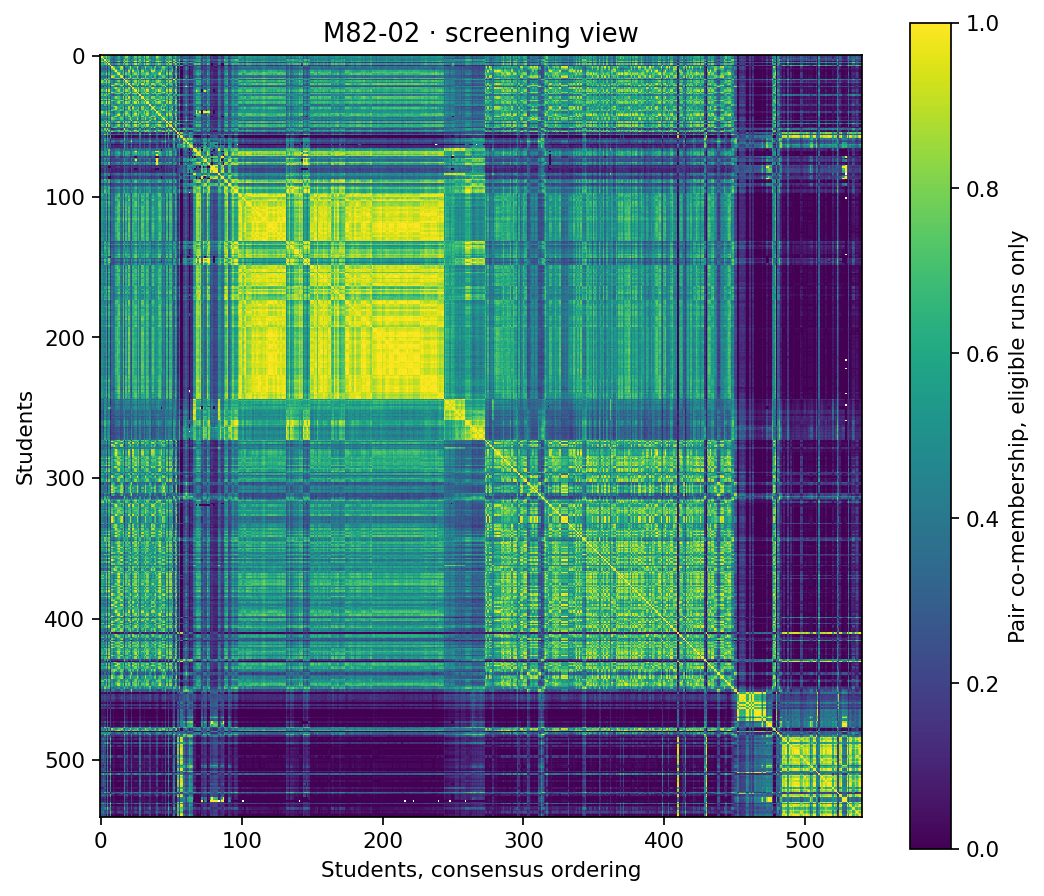

M82_02_view_01_task_behavior.png


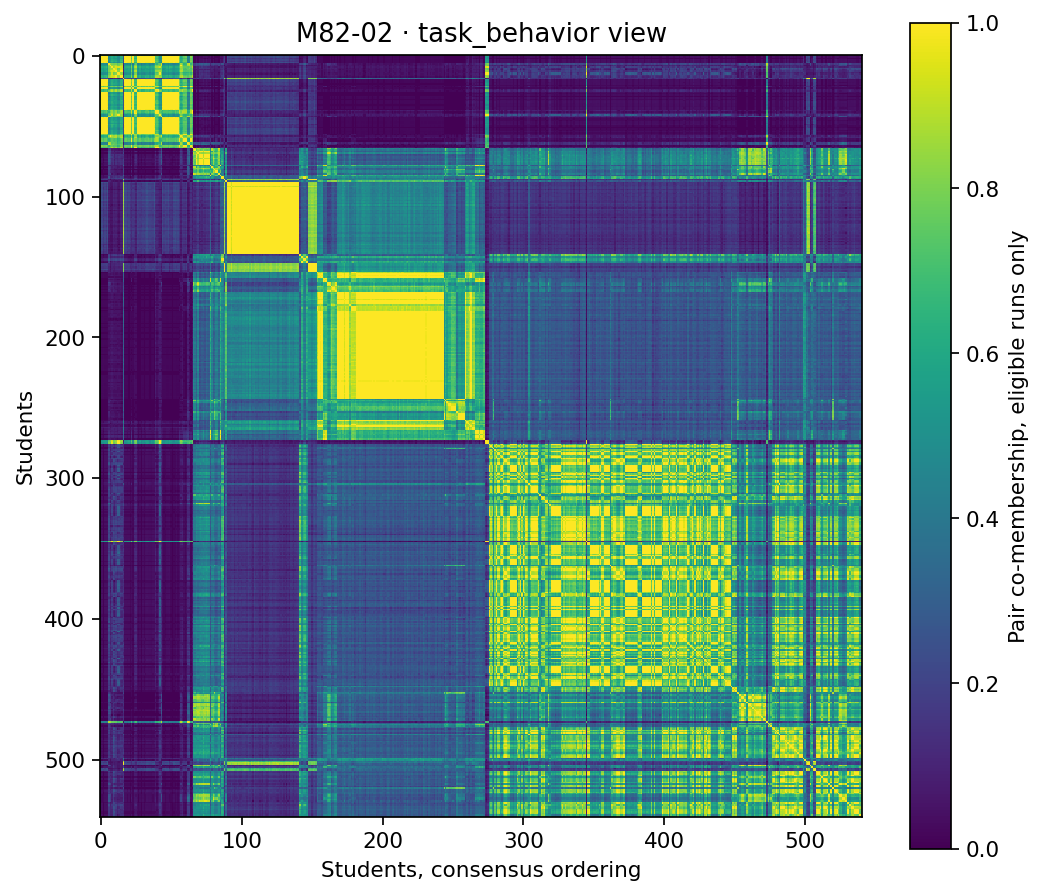

M82_02_view_02_acoustic_timing.png


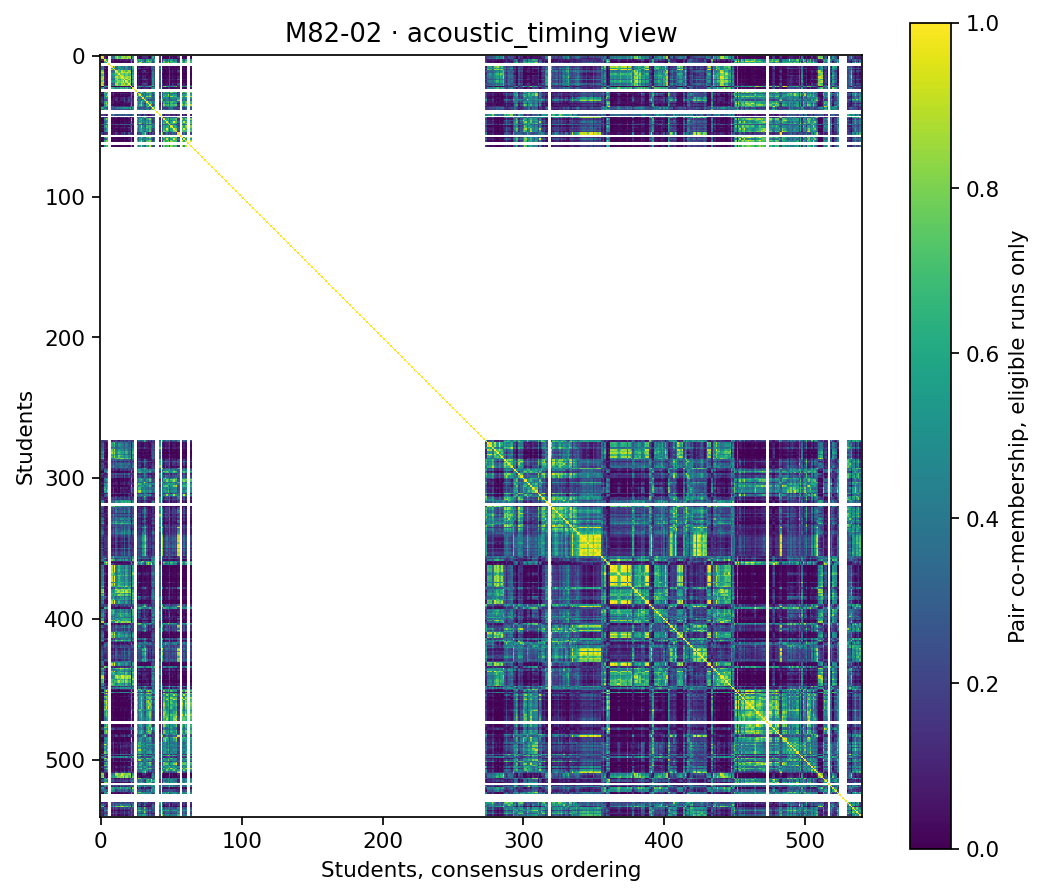

M82_02_view_03_acoustic_signal.png


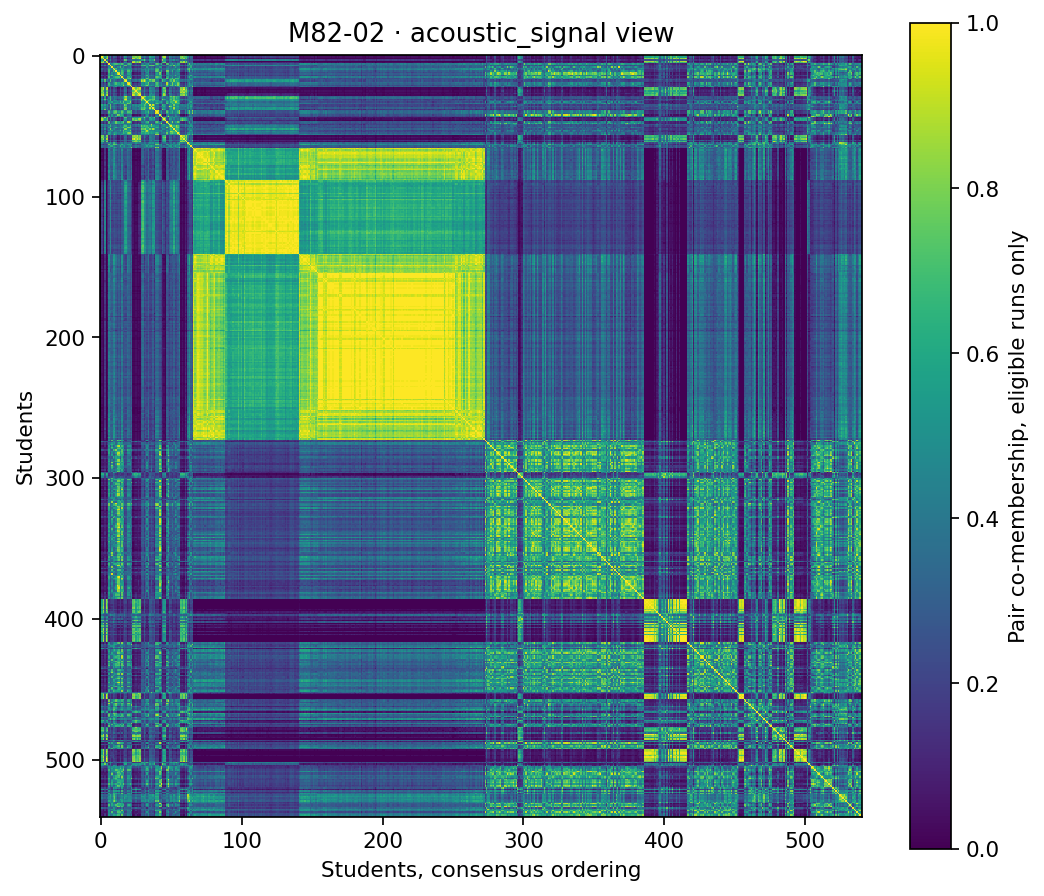

M82_02_view_04_phonetic_speech.png


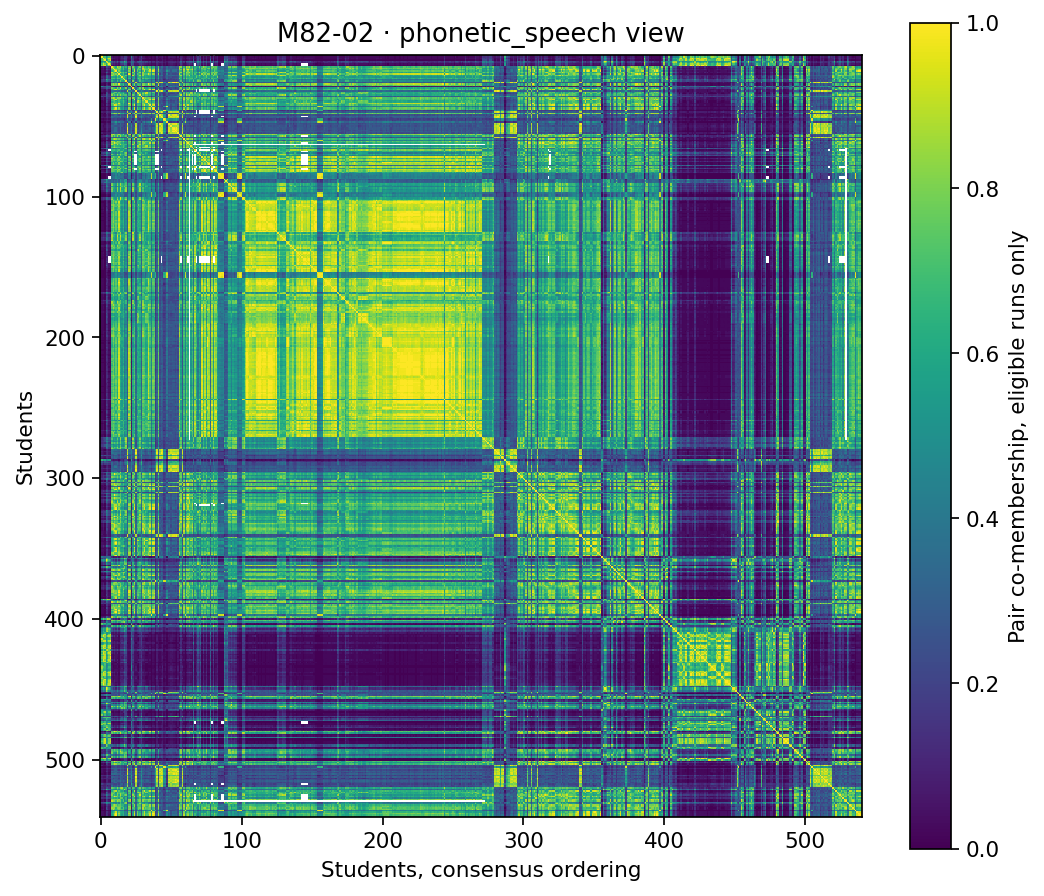

M82_02_view_05_conditional_speech.png


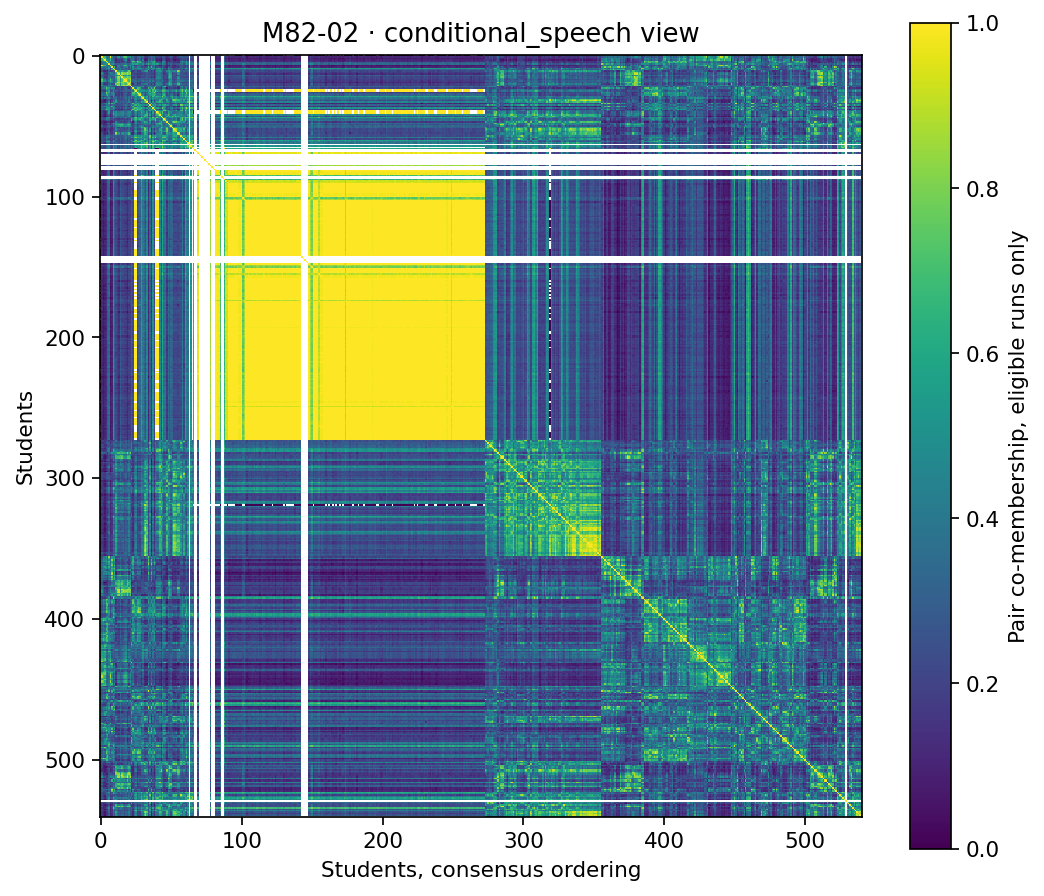

In [18]:
for name in ['M82_01_consensus_heatmap.png']+sorted([p.name for p in F.glob('M82_02_view_*.png')]):
    if (F/name).is_file():
        print(name)
        display(Image(filename=str(F/name)))


## 7 — Stable student relationships and outcome-discordant behavioral twins

stable_but_outcome_discordant.csv 200 pairs


,subject_a,subject_b,category,consensus,chance_expected,view_disagreement,score_gap,screening_residual_gap,same_school
0,6e3baacb2191,d77242ef096d,stable_together,0.952193,0.403432,0.108696,58.0,64.132607,True
1,0d854e089daa,6e3baacb2191,stable_together,0.952192,0.399922,0.127660,58.0,62.928217,False
2,6e3baacb2191,f03a4c375b7f,stable_together,0.953886,0.406321,0.117647,53.0,59.529232,True
3,85701569e040,d77242ef096d,stable_together,0.963953,0.400749,0.122449,46.0,56.068492,True
4,6e3baacb2191,74be983735a0,stable_together,0.914308,0.403560,0.215686,55.0,55.494127,False
5,6e3baacb2191,81a98d740711,stable_together,0.981101,0.410074,0.038462,60.0,55.156882,False
6,6e3baacb2191,d25879460566,stable_together,0.934894,0.413029,0.200000,58.0,54.874760,False
7,0d854e089daa,85701569e040,stable_together,0.966981,0.399833,0.132075,46.0,54.864103,False
8,6e3baacb2191,97db7f59fc8d,stable_together,0.961748,0.402968,0.092593,52.0,53.595553,True
9,22804e953caf,6e3baacb2191,stable_together,0.953897,0.410785,0.115385,52.0,53.555771,False


view_disagreement_pairs.csv 200 pairs


,subject_a,subject_b,category,consensus,chance_expected,view_disagreement,score_gap,screening_residual_gap,same_school
0,3ecc20ba90c8,42b8873bc89a,cross_view_disagreement,0.427729,0.389587,1.0,38.0,22.981503,False
1,cc1e01e66266,ceae179cbf76,cross_view_disagreement,0.590656,0.384790,1.0,4.0,4.588726,True
2,ceae179cbf76,ed5559d87244,cross_view_disagreement,0.426827,0.380609,1.0,4.0,18.774958,False
3,d96a6d9bf879,f6866d4691e7,cross_view_disagreement,0.516272,0.386143,1.0,13.0,12.501817,False
4,ceae179cbf76,f6396ce6787f,cross_view_disagreement,0.564828,0.377871,1.0,16.0,6.113234,False
5,ceae179cbf76,fd6a3e4ca8f2,cross_view_disagreement,0.503810,0.385871,1.0,5.0,4.428344,False
6,cede0a5da684,da6dd8390279,cross_view_disagreement,0.476192,0.402656,1.0,11.0,12.739561,False
7,d1493a6bf941,e60b8d5a1b71,cross_view_disagreement,0.432689,0.392890,1.0,8.0,20.436777,False
8,d150678234da,f21b54c498c7,cross_view_disagreement,0.421844,0.409371,1.0,10.0,10.794330,True
9,d1c0377d359b,d96a6d9bf879,cross_view_disagreement,0.517354,0.394750,1.0,8.0,8.430803,False


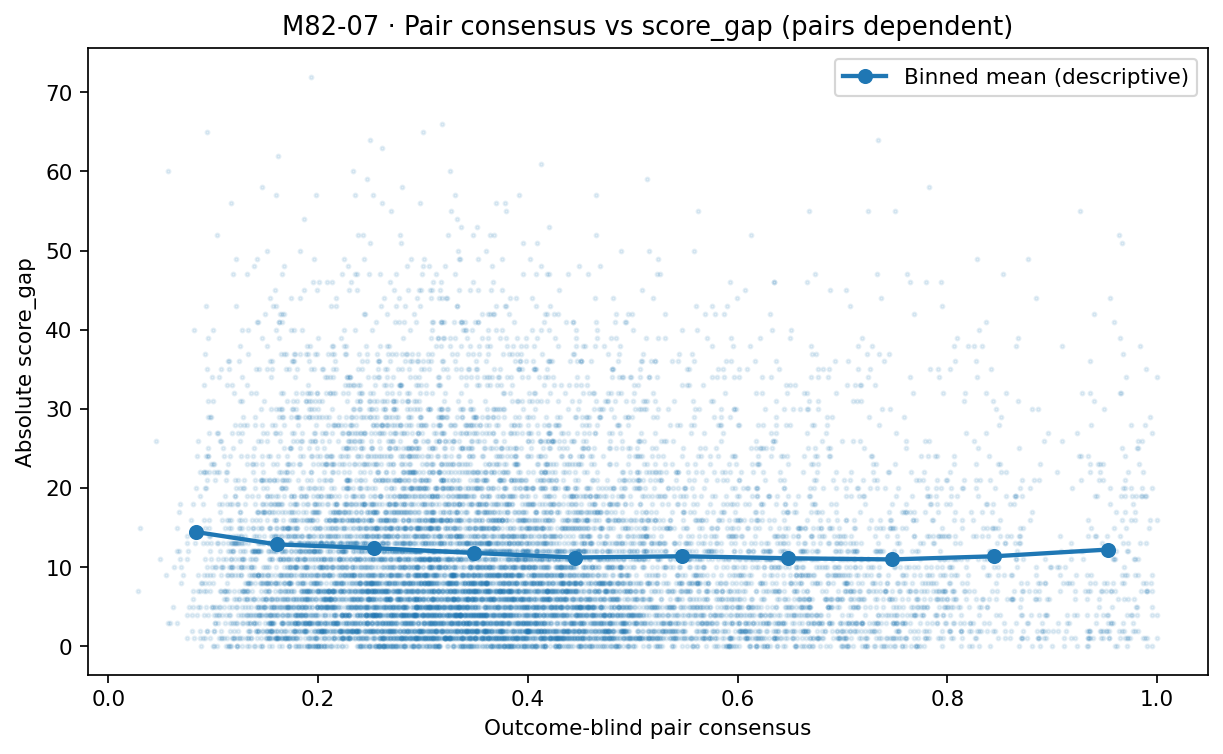

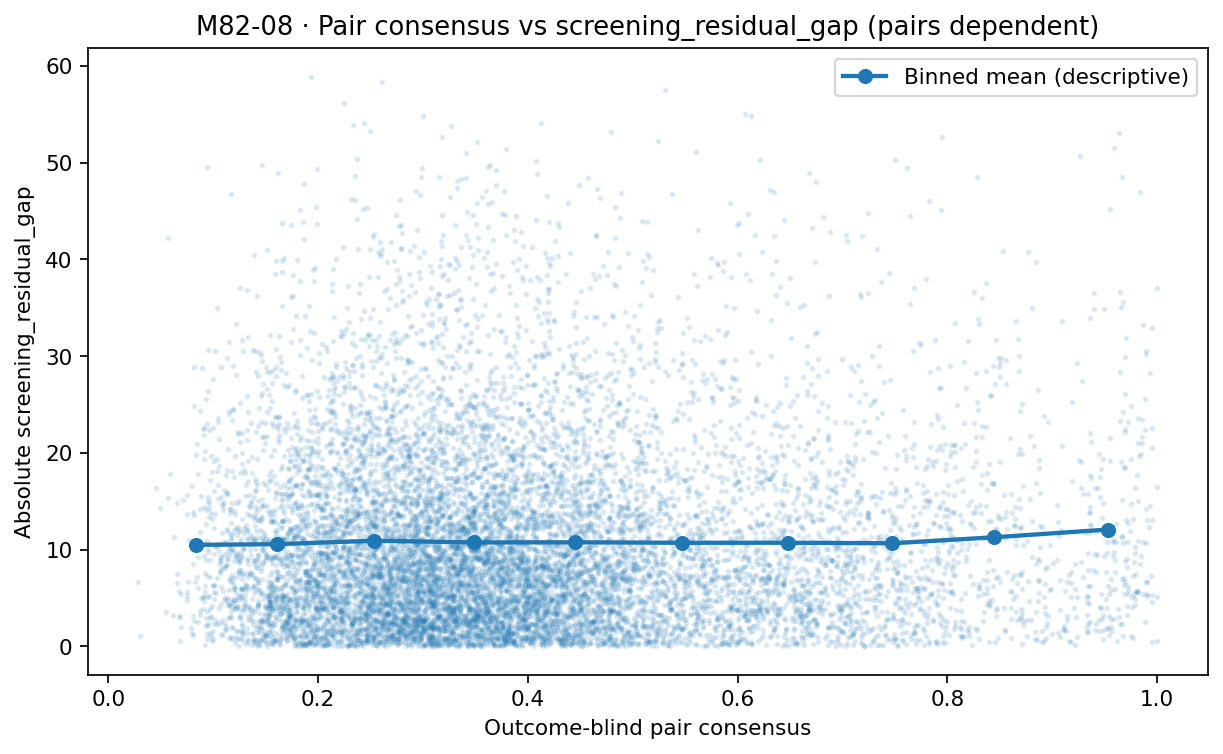

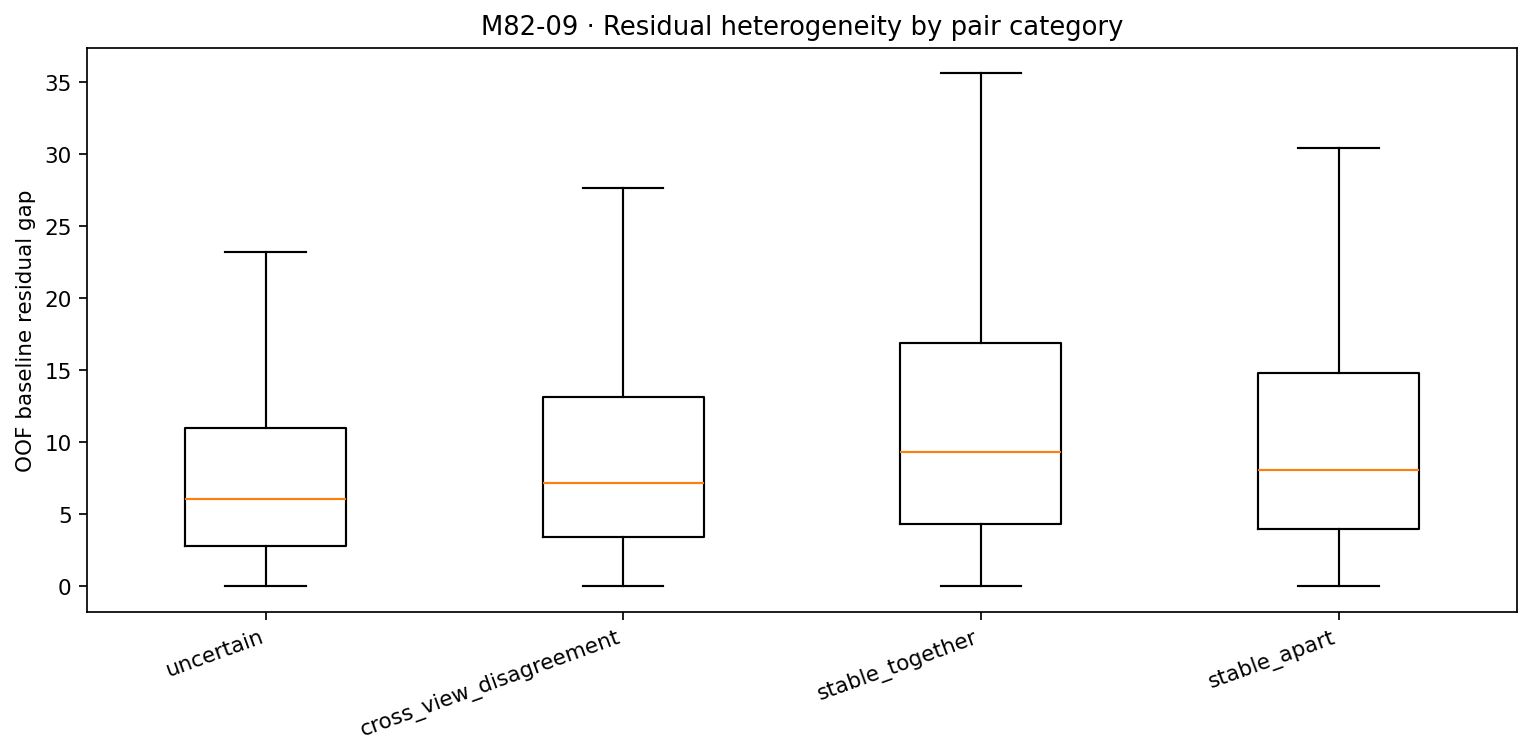

In [19]:
for name in ('stable_but_outcome_discordant.csv','view_disagreement_pairs.csv'):
    path=T/name
    if path.is_file():
        df=pd.read_csv(path,dtype={'subject_a':str,'subject_b':str})
        print(name,len(df),'pairs')
        wanted=['subject_a','subject_b','category','consensus','chance_expected','view_disagreement','score_gap','screening_residual_gap','same_school']
        display(df[[col for col in wanted if col in df]].head(25))
for name in ('M82_07_consensus_score_gap.png','M82_08_consensus_screening_residual_gap.png','M82_09_pair_residual_gap.png'):
    if (F/name).is_file():display(Image(filename=str(F/name)))


## 8 — Cross-view disagreement: agreement and recording/school confounding

,same_school,n_pairs,mean_consensus,stable_together_fraction,stable_apart_fraction
0,False,127106,0.3921,0.0155,0.0018
1,True,18964,0.4559,0.0339,0.0014


,target,descriptive_pairwise_spearman,pair_count_not_independent,interpretation
0,score_gap,-0.0614,146070,Exploratory only: pairs share students; do not...
1,screening_residual_gap,-0.0034,146070,Exploratory only: pairs share students; do not...


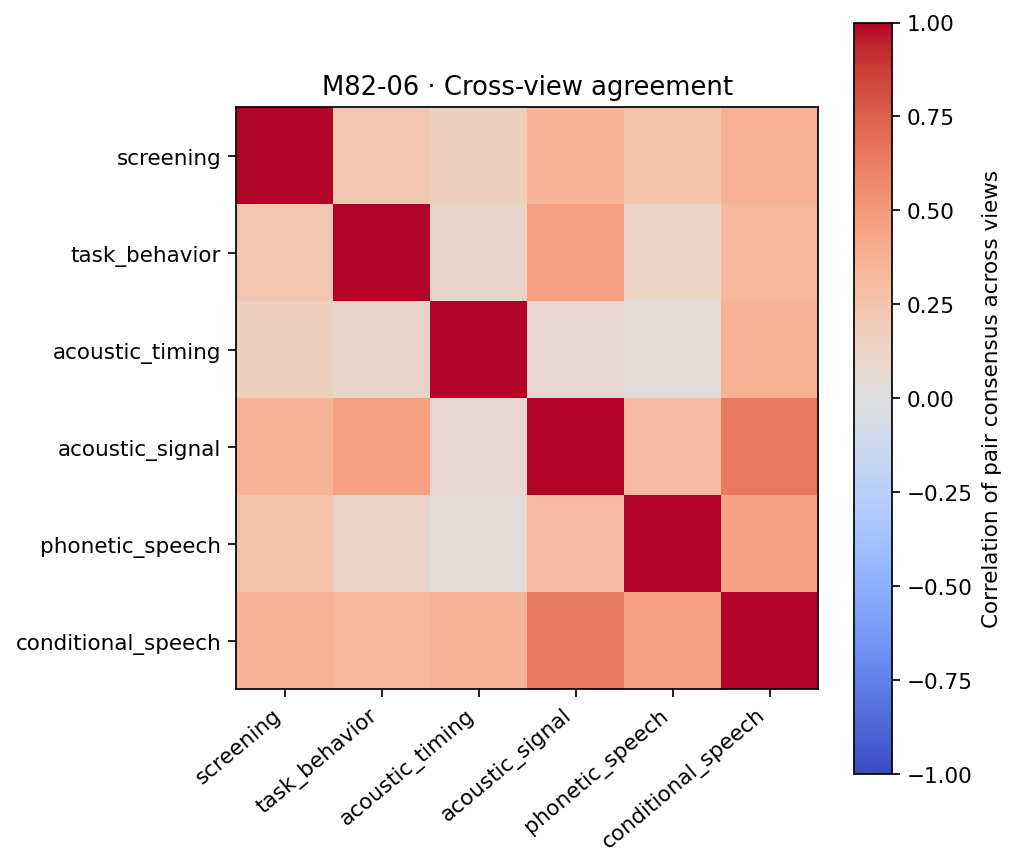

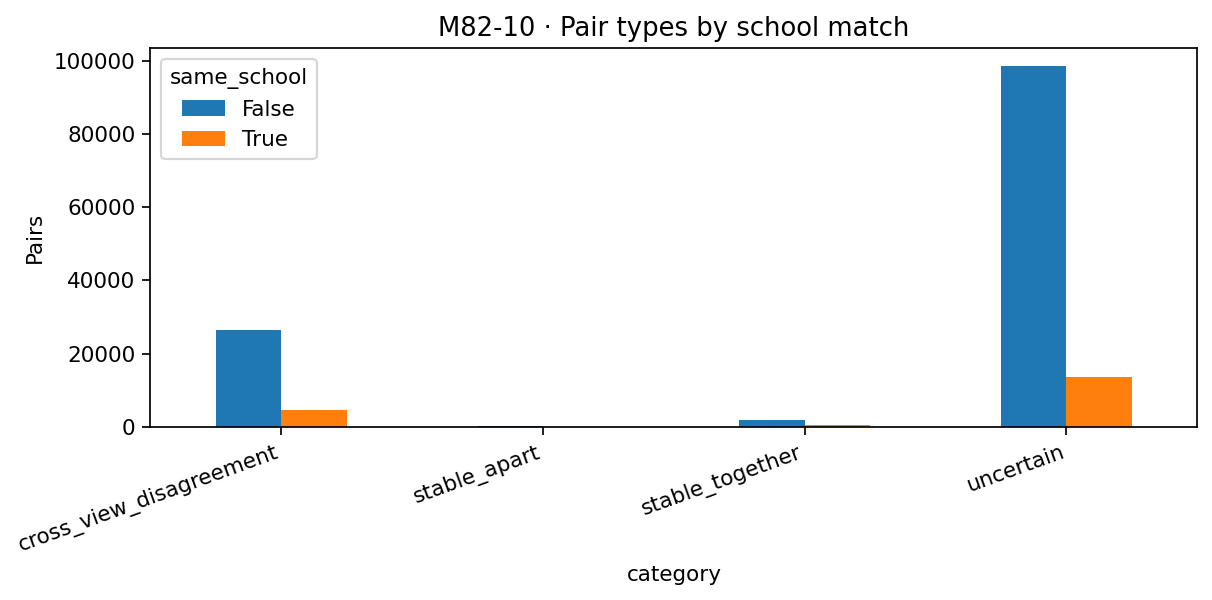

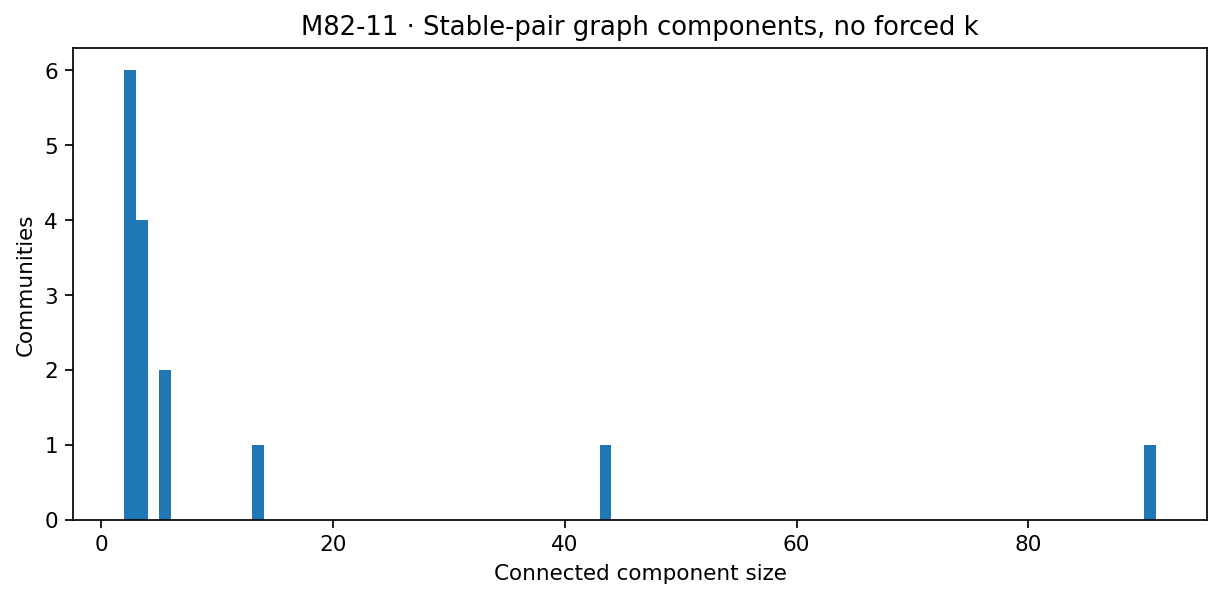

In [20]:
display(pd.read_csv(T/'school_confound_summary.csv').round(4))
display(pd.read_csv(T/'consensus_score_relationship.csv').round(4))
for name in ('M82_06_view_agreement.png','M82_10_school_pair_confound.png','M82_11_stable_graph_components.png'):
    if (F/name).is_file():display(Image(filename=str(F/name)))


## 9 — Optional inductive predictive validation

r2               mae              rmse  \
                                 mean      std     mean      std     mean   
model                                                                       
consensus_prototype_residual  0.20410  0.03238  7.28665  0.32782  9.83254   
global                        0.20416  0.03248  7.28413  0.34249  9.83259   

                                       
                                  std  
model                                  
consensus_prototype_residual  0.35856  
global                        0.37190

,delta_r2,lo95,hi95,delta_mae,resampling,n_students,n_schools
0,0.00007,-0.001895,0.001462,0.002535,student,541,17


,delta_r2,lo95,hi95,delta_mae,resampling,n_students,n_schools
0,0.00007,-0.001742,0.001484,0.002535,school_cluster,541,17


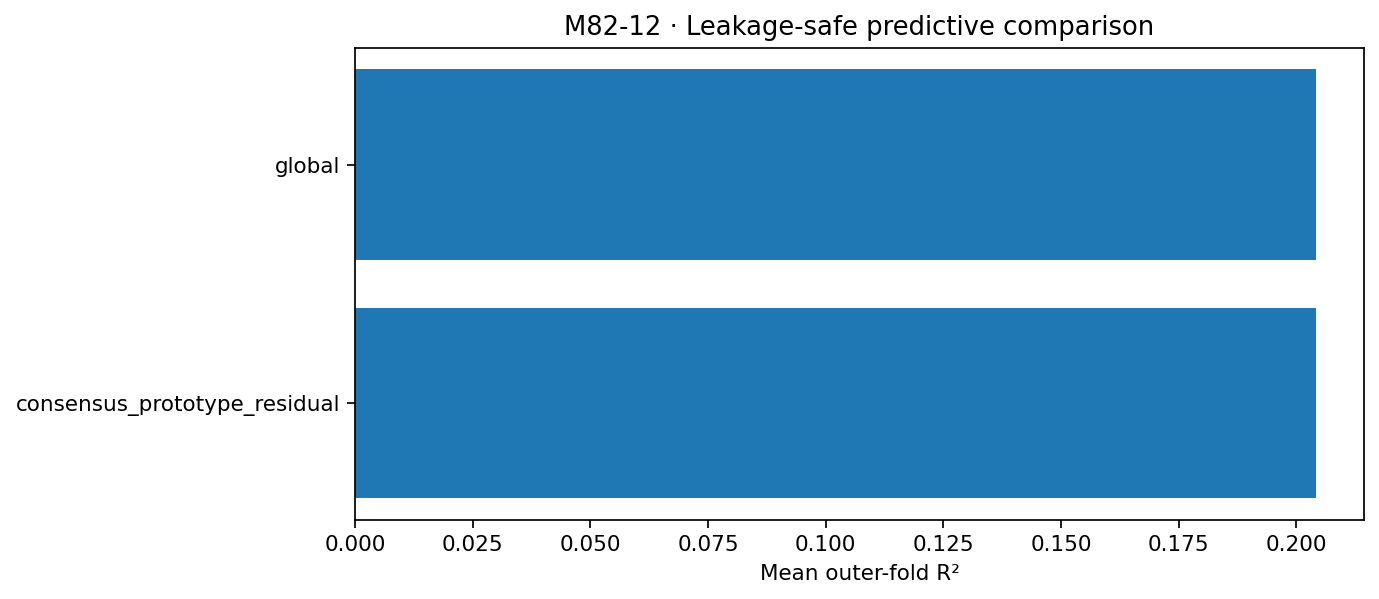

In [21]:
path=T/'pairwise_predictive_fold_metrics.csv'
if path.exists():
    z=pd.read_csv(path)
    display(z.groupby('model')[['r2','mae','rmse']].agg(['mean','std']).round(5))
    display(pd.read_csv(T/'pairwise_predictive_student_bootstrap.csv'))
    display(pd.read_csv(T/'pairwise_predictive_school_bootstrap.csv'))
    if (F/'M82_12_predictive_cv.png').exists():display(Image(filename=str(F/'M82_12_predictive_cv.png')))
else:
    print('Prediction not run. Change RUN_PREDICTIVE=True and rerun §4.')


## 10 — Read the automatic evidence report and open the figure atlas

In [22]:
report=OUT/'M82_RESEARCH_SUMMARY.md'
if report.exists():display(Markdown(report.read_text()))
print('Figure atlas:',OUT/'M82_RESEARCH_ATLAS.html')
print('Full pair table:',T/'all_student_pairs.parquet' if (T/'all_student_pairs.parquet').exists() else T/'all_student_pairs.csv.gz')
print('Generated figures:',len(list(F.glob('M82*.png'))))


# M8.2 Pairwise consensus evidence report

Analyzed **541 students** and **146070 unique student pairs**.

## View inventory

- **screening**: 25 features, mean available 87.2%
- **task_behavior**: 21 features, mean available 90.9%
- **acoustic_timing**: 36 features, mean available 70.2%
- **acoustic_signal**: 36 features, mean available 89.4%
- **phonetic_speech**: 20 features, mean available 89.1%
- **conditional_speech**: 92 features, mean available 81.8%
- **nuisance_audit_excluded**: 36 features, mean available 89.2%

## Pair categories

| category                |   n_pairs |   n_students_involved |   pct_all_pairs |   mean_consensus |   mean_chance_excess |   same_school_fraction |   mean_screening_distance |   median_score_gap |   mean_score_gap |   median_screening_residual_gap |   mean_screening_residual_gap |
|:------------------------|----------:|----------------------:|----------------:|-----------------:|---------------------:|-----------------------:|--------------------------:|-------------------:|-----------------:|--------------------------------:|------------------------------:|
| uncertain               |    111975 |                   541 |           0.767 |            0.370 |               -0.030 |                  0.121 |                     1.634 |              9.000 |           11.919 |                           8.361 |                        10.760 |
| cross_view_disagreement |     31224 |                   541 |           0.214 |            0.467 |                0.070 |                  0.151 |                     1.662 |              9.000 |           11.593 |                           8.145 |                        10.793 |
| stable_together         |      2618 |                   180 |           0.018 |            0.956 |                0.554 |                  0.245 |                     0.716 |              9.000 |           12.311 |                           9.313 |                        12.088 |
| stable_apart            |       253 |                   151 |           0.002 |            0.061 |               -0.332 |                  0.107 |                     2.293 |             11.000 |           13.182 |                           8.035 |                        10.204 |

## Interpretation safeguards

- Outcome scores not used to construct consensus
- Pair observations are dependent, not independent samples
- Null expected consensus is chance correction, not p-value
- No audio re-extraction; phonetic view requires existing feature cache
- Full unvalidated study; figures are descriptive; validate out of school

## Outer-fold predictive comparator

| model                        |     r2 |    mae |   rmse |
|:-----------------------------|-------:|-------:|-------:|
| consensus_prototype_residual | 0.2041 | 7.2866 | 9.8325 |
| global                       | 0.2042 | 7.2841 | 9.8326 |

The correction is fixed-strength and trained on **OOF residuals from training students only**. A gain must replicate before deployment.

Figure atlas: /content/drive/MyDrive/WildSpeech_M8/m82/M82_RESEARCH_ATLAS.html
Full pair table: /content/drive/MyDrive/WildSpeech_M8/m82/tables/all_student_pairs.parquet
Generated figures: 17


## 11 — How to interpret the findings

- **Stable together** means reproducible co-clustering in the tested feature views; it is **not** proof of a biological or educational type.
- **Stable apart** is chance-adjusted; the base chance depends on actual cluster size and cluster count.
- **Low coverage** is not similarity. Two missing values must not create a false stable pair.
- Pair-level Spearman and gap distributions are descriptive; student pairs are not independent.
- Identical validation folds are used for global and structural-prototype residual models.
- Group outcome differences are **not** used to build the unsupervised consensus; they are analyzed afterward.
- If stable pairs are mostly explained by school or recording conditions, remove those signals and repeat.
- Do not use the most promising pair groups to select a leaderboard model without further independent validation.
- `SMOKE` outputs are only pipeline diagnostics. For scientific interpretation use `FULL` on the complete M8.1 feature bank.